# Stroke-3 Transformer: local training

Run cells in order using a Python kernel with PyTorch, NumPy, matplotlib and tqdm.
Your existing `vector-classification` Conda environment has these dependencies.
If it is not listed in Jupyter, register it from a terminal:
`conda run -n vector-classification python -m ipykernel install --user --name vector-classification --display-name "Vector classification"`.
Select **Vector classification** as the notebook kernel.

**Architecture:** stroke-3 → Linear(3,128) → fixed sinusoidal point positions + learned
CLS token → 4 pre-norm Transformer blocks (4 heads, FFN 384, GELU) → final LayerNorm
on CLS → Linear(128,345). Residual/FFN dropout 0.1; attention-weight dropout 0.
Full bidirectional attention masks padding. No derived coordinates, stroke embeddings,
input LayerNorm, or pooling variants.

The notebook is self-contained; it does not import from the Copy folder or archived code.
It uses the existing memory-mapped local cache without resampling or normalizing again.
The dataset audit checks all three split ID lists against the saved last-state run,
and checks preprocessing metadata against the existing local LSTM. The remote last-state
manifest differs: matching IDs alone does not certify identical remote preprocessing.
This distinction is recorded with the new run.

**Run all** audits the data, runs short synthetic model checks, and trains for 10 epochs.
The held-out test cell stays off until you set `RUN_FINAL_TEST=True` after choosing settings.
Outputs go to a new timestamped directory. Existing checkpoints are never overwritten.

In [1]:
from pathlib import Path
from datetime import datetime
from contextlib import nullcontext
import copy, gzip, hashlib, json, math, random, time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/experiment_345_seed42').is_dir()
             and (p / 'src').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the original vector-sketch-classification folder.')
CACHE = ROOT / 'data/experiment_345_seed42'
DATA = ROOT / 'data/processed_full'
REFERENCE_IDS = ROOT / 'results/lstm_baseline_reference_seed42'
LOCAL_LSTM = ROOT / 'results/bilstm_345_matched_seed42'

CFG = dict(seed=42, epochs=10, batch_size=128, lr=3e-4, weight_decay=0.01,
           warmup_fraction=0.05, grad_clip=1.0,
           dim=128, heads=4, layers=4, ff_dim=384, dropout=0.1, max_length=250)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Optional mixed precision on CUDA; float32 on CPU. No GradScaler is needed for bfloat16.
USE_BF16 = DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported()
torch.set_num_threads(4)
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(CFG['seed'])
def autocast_context():
    return torch.autocast('cuda', dtype=torch.bfloat16) if USE_BF16 else nullcontext()
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))
def save_json(path, value):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(value, indent=2) + '\n', encoding='utf-8')
    temp.replace(path)
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()
print('Project:', ROOT)
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU (full training will be slow)')
print('PyTorch:', torch.__version__, '| bfloat16:', USE_BF16)

Project: c:\Users\shrua\OneDrive\Desktop\11785 IDL\vector-sketch-classification
Device: NVIDIA GeForce RTX 5060 Laptop GPU
PyTorch: 2.11.0+cu128 | bfloat16: True


c:\Users\shrua\anaconda3\envs\vector-classification\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Audit the existing splits

This reads IDs/metadata and hashes cache files, including the point arrays, to make the
training inputs traceable. It does not load the full point arrays into RAM. Split counts
must be 5,000 / 500 / 500 per category across all 345 categories. Missing data or mismatches
stop execution instead of silently drawing a new subset. Test inputs are audited here;
test predictions and metrics are computed only in the final-test cell.

In [2]:
def audit_data():
    manifest = read_json(DATA / 'manifest.json')
    if manifest['representation'] != 'stroke-3' or manifest['normalization']['fit_split'] != 'train':
        raise ValueError('Expected training-normalized stroke-3 data.')
    if manifest['archive_version'] != 'full':
        raise ValueError('Expected full archives.')
    categories = sorted(manifest['class_to_index'], key=manifest['class_to_index'].get)
    if len(categories) != 345:
        raise ValueError('Expected 345 categories.')
    source_hash = sha256(DATA / 'manifest.json')
    reference_cfg = read_json(REFERENCE_IDS / 'config.json')
    if reference_cfg['data']['categories'] != categories:
        raise ValueError('Category order differs from the earlier last-state run.')
    local_provenance = read_json(LOCAL_LSTM / 'provenance.json')
    audit, split_ids = {}, {}
    for split, per_class in [('train',5000), ('valid',500), ('test',500)]:
        folder = CACHE / split
        meta = read_json(folder / 'metadata.json')
        spec = meta['specification']
        expected = dict(source_manifest_sha256=source_hash, split=split,
                        per_class=per_class, max_length=250, seed=42, categories=categories)
        if any(spec.get(k) != v for k,v in expected.items()) or meta['scale_factor'] != 1.0:
            raise ValueError(f'{split}: cache preprocessing/sampling specification mismatch.')
        with gzip.open(folder / 'sample_ids.txt.gz', 'rt', encoding='utf-8') as f:
            ids = f.read().splitlines()
        if ids != read_json(REFERENCE_IDS / f'{split}_sample_ids.json'):
            raise ValueError(f'{split}: ordered sample IDs differ from the earlier last-state run.')
        ids_hash = hashlib.sha256(''.join(x+'\n' for x in ids).encode()).hexdigest()
        if len(ids) != len(set(ids)) or ids_hash != meta['sample_ids_sha256']:
            raise ValueError(f'{split}: invalid IDs/hash.')
        if split in ('train', 'valid'):
            earlier = local_provenance[split]
            for key in ('specification','samples','points','sample_ids_sha256','scale_factor','coordinate_scale','class_counts'):
                if meta[key] != earlier[key]:
                    raise ValueError(f'{split}: metadata differs from local LSTM: {key}')
        labels = np.load(folder / 'labels.npy', mmap_mode='r')
        offsets = np.load(folder / 'offsets.npy', mmap_mode='r')
        points = np.load(folder / 'points.npy', mmap_mode='r')
        lengths = np.diff(offsets)
        if len(labels) != len(ids) or len(ids) != 345*per_class or len(offsets) != len(ids)+1:
            raise ValueError(f'{split}: sample count mismatch.')
        if not np.issubdtype(labels.dtype, np.integer) or np.any(labels < 0) or np.any(labels >= 345):
            raise ValueError(f'{split}: invalid labels.')
        if not np.all(np.bincount(labels, minlength=345) == per_class):
            raise ValueError(f'{split}: class counts differ.')
        if offsets[0] != 0 or offsets[-1] != len(points) or points.shape != (meta['points'],3):
            raise ValueError(f'{split}: invalid point/offset arrays.')
        if points.dtype != np.float32 or np.any(lengths < 1) or np.any(lengths > 250):
            raise ValueError(f'{split}: invalid dtype/lengths.')
        # Scan in chunks: validate all features without loading a full split into RAM.
        for start in range(0, len(points), 1_000_000):
            chunk = points[start:start+1_000_000]
            if not np.isfinite(chunk).all() or not np.isin(chunk[:,2], [0,1]).all():
                raise ValueError(f'{split}: invalid stroke-3 features.')
        if any(not identifier.startswith(categories[int(label)]+'/full/'+split+'/')
               for identifier,label in zip(ids,labels)):
            raise ValueError(f'{split}: IDs and labels disagree.')
        hashes = {name:sha256(folder/name) for name in
                  ['points.npy','offsets.npy','labels.npy','sample_ids.txt.gz','metadata.json']}
        audit[split] = dict(samples=len(ids), sample_ids_sha256=ids_hash,
                            cache_files_sha256=hashes, metadata=meta)
        split_ids[split] = set(ids)
        print(f'{split}: {len(ids):,} sketches; exact earlier IDs verified')
    if any(split_ids[a] & split_ids[b] for a,b in [('train','valid'),('train','test'),('valid','test')]):
        raise ValueError('Splits overlap.')
    remote_hash = reference_cfg['data']['preprocessing']['manifest_sha256']
    audit['comparison'] = dict(local_lstm_metadata_matches=True, all_last_state_ids_match=True,
        current_manifest_sha256=source_hash, remote_manifest_sha256=remote_hash,
        remote_preprocessing_equivalence_certified=(source_hash == remote_hash))
    print('Local LSTM preprocessing metadata matches. Remote manifest matches:', source_hash == remote_hash)
    return categories, audit

CATEGORIES, DATA_AUDIT = audit_data()

train: 1,725,000 sketches; exact earlier IDs verified
valid: 172,500 sketches; exact earlier IDs verified
test: 172,500 sketches; exact earlier IDs verified
Local LSTM preprocessing metadata matches. Remote manifest matches: False


## 2. Memory-mapped batches

Only a batch moves to RAM/GPU. Training shuffles samples every epoch; validation/test
preserve source order. Padding is to the longest sketch in the batch. No Windows worker
processes are needed, and no coordinates are renormalized.

In [3]:
class CachedSplit:
    def __init__(self, split):
        folder = CACHE / split
        self.points = np.load(folder/'points.npy', mmap_mode='r')
        self.offsets = np.load(folder/'offsets.npy', mmap_mode='r')
        self.labels = np.load(folder/'labels.npy', mmap_mode='r')
        self.lengths = np.diff(self.offsets)
    def __len__(self):
        return len(self.labels)
    def batch(self, indices):
        indices = np.asarray(indices, dtype=np.int64)
        lengths = self.lengths[indices]
        steps = np.arange(int(lengths.max()))[None,:]
        valid = steps < lengths[:,None]
        gather = self.offsets[indices,None] + np.minimum(steps, lengths[:,None]-1)
        strokes = np.asarray(self.points[gather]).copy()
        strokes[~valid] = 0
        return (torch.from_numpy(strokes).to(DEVICE),
                torch.from_numpy(lengths.copy()).long().to(DEVICE),
                torch.from_numpy(np.asarray(self.labels[indices]).copy()).long().to(DEVICE))
    def batches(self, batch_size, shuffle=False, seed=42):
        order = np.random.default_rng(seed).permutation(len(self)) if shuffle else np.arange(len(self))
        for start in range(0,len(self),batch_size):
            yield self.batch(order[start:start+batch_size])

train_data, valid_data = CachedSplit('train'), CachedSplit('valid')

## 3. The agreed architecture

Each block applies LayerNorm before attention and before the FFN. Each block is initialized
independently. For PyTorch scaled-dot-product attention, Boolean `True` means a key is valid
(the opposite convention from `key_padding_mask`). CLS is always valid. Attention dropout
is explicitly zero during both training and evaluation.

[PyTorch attention API](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html)

In [4]:
class AttentionBlock(nn.Module):
    def __init__(self, dim, heads, ff_dim, dropout):
        super().__init__()
        self.heads = heads
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim,3*dim)
        self.out = nn.Linear(dim,dim)
        self.ff = nn.Sequential(nn.Linear(dim,ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim,dim))
        self.drop = nn.Dropout(dropout)
    def forward(self, x, valid):
        b,t,d = x.shape
        q,k,v = self.qkv(self.norm1(x)).reshape(b,t,3,self.heads,d//self.heads).permute(2,0,3,1,4).unbind(0)
        attended = F.scaled_dot_product_attention(q,k,v,attn_mask=valid[:,None,None,:],
                                                  dropout_p=0.0, is_causal=False)
        x = x + self.drop(self.out(attended.transpose(1,2).reshape(b,t,d)))
        return x + self.drop(self.ff(self.norm2(x)))

class StrokeTransformer(nn.Module):
    def __init__(self, dim=128, heads=4, layers=4, ff_dim=384, dropout=0.1, max_length=250):
        super().__init__()
        if dim % heads or dim % 2:
            raise ValueError('dim must be even and divisible by heads.')
        self.embedding_dim, self.max_length = dim, max_length
        self.input = nn.Linear(3,dim)
        self.cls = nn.Parameter(torch.empty(1,1,dim))
        nn.init.normal_(self.cls, std=0.02)
        positions = torch.arange(max_length,dtype=torch.float32)[:,None]
        frequencies = torch.exp(torch.arange(0,dim,2,dtype=torch.float32)*(-math.log(10000.0)/dim))
        encoding = torch.zeros(max_length,dim)
        encoding[:,0::2] = torch.sin(positions*frequencies)
        encoding[:,1::2] = torch.cos(positions*frequencies)
        self.register_buffer('positions', encoding[None,:,:])
        self.blocks = nn.ModuleList([AttentionBlock(dim,heads,ff_dim,dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(dim)
    def forward(self, strokes, lengths):
        if strokes.ndim != 3 or strokes.shape[-1] != 3:
            raise ValueError('Expected strokes [B,T,3].')
        b,t,_ = strokes.shape
        if not 1 <= t <= self.max_length or lengths.shape != (b,):
            raise ValueError('Invalid sequence width or lengths shape.')
        lengths = lengths.to(strokes.device)
        if lengths.dtype not in (torch.int32,torch.int64) or torch.any(lengths < 1) or torch.any(lengths > t):
            raise ValueError('Lengths must be integer values in [1,T].')
        valid = torch.arange(t,device=strokes.device)[None,:] < lengths[:,None]
        # Remove arbitrary padded values before projecting; real zero points stay valid.
        x = self.input(strokes.masked_fill(~valid[:,:,None],0))
        x = x + self.positions[:,:t].to(x.dtype)
        x = torch.cat([self.cls.expand(b,-1,-1),x],dim=1)
        valid = torch.cat([torch.ones(b,1,dtype=torch.bool,device=strokes.device),valid],dim=1)
        for block in self.blocks:
            x = block(x,valid)
        return self.norm(x[:,0])

class SketchClassifier(nn.Module):
    def __init__(self, num_classes=345, **encoder_kwargs):
        super().__init__()
        self.encoder = StrokeTransformer(**encoder_kwargs)
        self.head = nn.Linear(self.encoder.embedding_dim,num_classes)
    def embed(self, strokes, lengths):
        return self.encoder(strokes,lengths)
    def forward(self, strokes, lengths):
        return self.head(self.embed(strokes,lengths))

MODEL_CFG = {k:CFG[k] for k in ['dim','heads','layers','ff_dim','dropout','max_length']}
def make_model(num_classes=345):
    return SketchClassifier(num_classes, **MODEL_CFG).to(DEVICE)
model = make_model()
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

SketchClassifier(
  (encoder): StrokeTransformer(
    (input): Linear(in_features=3, out_features=128, bias=True)
    (blocks): ModuleList(
      (0-3): 4 x AttentionBlock(
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (qkv): Linear(in_features=128, out_features=384, bias=True)
        (out): Linear(in_features=128, out_features=128, bias=True)
        (ff): Sequential(
          (0): Linear(in_features=128, out_features=384, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.1, inplace=False)
          (3): Linear(in_features=384, out_features=128, bias=True)
        )
        (drop): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  )
  (head): Linear(in_features=128, out_features=345, bias=True)
)
Trainable parameters: 706905


## 4. Quick synthetic checks

Checks shapes, padding invariance, mixed-length batches, boundary lengths, finite gradients,
checkpoint reload and learning on a tiny synthetic batch. This is not a QuickDraw score.
The sanity model is discarded before training.

In [5]:
def model_checks():
    seed_all(7)
    probe = make_model(3).eval()
    x = torch.randn(3,9,3,device=DEVICE)
    lengths = torch.tensor([9,5,1],device=DEVICE)
    with torch.no_grad():
        original = probe(x,lengths)
        assert original.shape == (3,3)
        extended = F.pad(x,(0,0,0,6),value=123.0)
        torch.testing.assert_close(original,probe(extended,lengths),atol=2e-5,rtol=2e-5)
        changed = x.clone()
        changed[1,5:] = -999; changed[2,1:] = 999
        torch.testing.assert_close(original,probe(changed,lengths),atol=2e-5,rtol=2e-5)
        torch.testing.assert_close(original[1:2],probe(x[1:2,:5],lengths[1:2]),atol=2e-5,rtol=2e-5)
        assert probe(torch.zeros(1,250,3,device=DEVICE),torch.tensor([250],device=DEVICE)).shape == (1,3)
        for bad in [torch.tensor([0,5,1],device=DEVICE),torch.tensor([10,5,1],device=DEVICE)]:
            try: probe(x,bad)
            except ValueError: pass
            else: raise AssertionError('Invalid lengths accepted')
    # In-memory torch serialization verifies state-dict save/load behavior.
    import io
    buffer = io.BytesIO()
    torch.save(probe.state_dict(),buffer); buffer.seek(0)
    restored = make_model(3).eval()
    restored.load_state_dict(torch.load(buffer,map_location=DEVICE,weights_only=True))
    with torch.no_grad():
        torch.testing.assert_close(original,restored(x,lengths))
    labels = torch.arange(3,device=DEVICE)
    optimizer = torch.optim.AdamW(probe.parameters(),lr=0.002)
    # Eval disables dropout while retaining gradients, isolating the learning check.
    before = float(F.cross_entropy(probe(x,lengths),labels).detach())
    for _ in range(60):
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(probe(x,lengths),labels)
        loss.backward()
        assert all(torch.isfinite(p.grad).all() for p in probe.parameters() if p.grad is not None)
        torch.nn.utils.clip_grad_norm_(probe.parameters(),1.0)
        optimizer.step()
    with torch.no_grad():
        after = float(F.cross_entropy(probe(x,lengths),labels))
        assert after < before*0.3 and torch.equal(probe(x,lengths).argmax(1),labels)
    print(f'PASS: model checks; synthetic loss {before:.4f} -> {after:.4f}')
model_checks()
seed_all(CFG['seed'])
model = make_model()

PASS: model checks; synthetic loss 1.1805 -> 0.0003


## 5. Training and checkpoint functions

AdamW (learning rate 0.0003, weight decay 0.01), plain cross-entropy, batch 128,
gradient clipping 1.0. Warm up for 5% of optimizer steps, then cosine decay to zero.
Keep all 10 epochs; select `best.pt` by validation top-1 only. Timing includes batching,
transfer and model work, with GPU synchronization at epoch boundaries. Save `last.pt`
after every epoch for exact epoch-boundary resume on the same environment.

In [6]:
def synchronize():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

def run_epoch(model, data, optimizer=None, epoch=0, step=0, total_steps=1):
    training = optimizer is not None
    model.train(training)
    warmup = max(1,round(total_steps*CFG['warmup_fraction']))
    sums = torch.zeros(4,device=DEVICE,dtype=torch.float64)
    synchronize(); start = time.perf_counter()
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        batches = data.batches(CFG['batch_size'],shuffle=training,seed=CFG['seed']+epoch)
        for x,lengths,labels in tqdm(batches,total=math.ceil(len(data)/CFG['batch_size']),
                                     desc=f'{"train" if training else "valid/test"} {epoch}',leave=False):
            if training:
                factor = ((step+1)/warmup if step < warmup else
                          0.5*(1+math.cos(math.pi*min(1,(step-warmup)/max(1,total_steps-warmup-1)))))
                for group in optimizer.param_groups: group['lr'] = CFG['lr']*factor
                optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                logits = model(x,lengths)
                loss = F.cross_entropy(logits,labels)
            if not torch.isfinite(loss): raise FloatingPointError('Nonfinite loss.')
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),CFG['grad_clip'],error_if_nonfinite=True)
                optimizer.step(); step += 1
            top = logits.topk(min(5,logits.shape[1]),dim=1).indices
            sums += torch.stack([loss.detach().double()*len(labels),
                                 (top[:,0]==labels).sum().double(),
                                 (top==labels[:,None]).any(1).sum().double(),
                                 torch.tensor(len(labels),device=DEVICE,dtype=torch.float64)])
    synchronize(); elapsed = time.perf_counter()-start
    loss_sum,correct,top5,count = sums.tolist()
    return dict(loss=loss_sum/count,acc=correct/count,top5_acc=top5/count,
                samples=int(count),seconds=elapsed),step

def save_checkpoint(path, payload):
    temp = Path(path).with_suffix('.tmp')
    torch.save(payload,temp); temp.replace(path)

def train_local(resume_dir=None):
    # One fresh folder per run. Pass an existing run directory only for intentional resume.
    out = (Path(resume_dir).resolve() if resume_dir else
           ROOT/'results'/('transformer_stroke3_local_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f')))
    seed_all(CFG['seed'])
    model = make_model()
    optimizer = torch.optim.AdamW(model.parameters(),lr=CFG['lr'],weight_decay=CFG['weight_decay'])
    history, first, step, best = [],1,0,-1.0
    if resume_dir:
        if read_json(out/'config.json') != CFG or read_json(out/'data_audit.json') != DATA_AUDIT:
            raise ValueError('Resume configuration/data differs from this notebook.')
        # Only load checkpoints produced by this notebook and trusted by you.
        ckpt = torch.load(out/'last.pt',map_location='cpu',weights_only=False)
        model.load_state_dict(ckpt['model_state']); optimizer.load_state_dict(ckpt['optimizer_state'])
        history,first,step,best = ckpt['history'],ckpt['epoch']+1,ckpt['step'],ckpt['best_acc']
        random.setstate(ckpt['python_rng']); np.random.set_state(ckpt['numpy_rng'])
        torch.set_rng_state(ckpt['torch_rng'])
        if DEVICE.type == 'cuda': torch.cuda.set_rng_state_all(ckpt['cuda_rng'])
    else:
        out.mkdir(parents=True,exist_ok=False)
        save_json(out/'config.json',CFG); save_json(out/'data_audit.json',DATA_AUDIT)
        save_json(out/'provenance.json',dict(torch=torch.__version__,numpy=np.__version__,
            device=str(DEVICE),gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
            precision='bfloat16 autocast' if USE_BF16 else 'float32',
            parameters=sum(p.numel() for p in model.parameters()),categories=CATEGORIES,
            architecture='stroke3-sinusoidal-cls-4x128-h4-ff384',
            test_used_for_selection=False))
        # Snapshot exactly the code used, even when the user edits notebook cells.
        source = '\n\n'.join(cell for cell in globals().get('In',[]) if cell and 'def ' in cell)
        (out/'executed_definitions.py.txt').write_text(source,encoding='utf-8')
    print('Outputs:',out)
    total_steps = CFG['epochs']*math.ceil(len(train_data)/CFG['batch_size'])
    for epoch in range(first,CFG['epochs']+1):
        if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
        train_metrics,step = run_epoch(model,train_data,optimizer,epoch,step,total_steps)
        valid_metrics,_ = run_epoch(model,valid_data,epoch=epoch)
        history.append(dict(epoch=epoch,train=train_metrics,valid=valid_metrics,
            peak_gpu_memory_bytes=torch.cuda.max_memory_allocated() if DEVICE.type=='cuda' else None))
        improved = valid_metrics['acc'] > best
        best = max(best,valid_metrics['acc'])
        payload = dict(epoch=epoch,step=step,best_acc=best,config=CFG,
            model_state=model.state_dict(),optimizer_state=optimizer.state_dict(),history=history,
            python_rng=random.getstate(),numpy_rng=np.random.get_state(),torch_rng=torch.get_rng_state(),
            cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])
        if improved: save_checkpoint(out/'best.pt',payload)
        save_checkpoint(out/'last.pt',payload)
        save_json(out/'history.json',history)
        print(f"Epoch {epoch:02d} | train {train_metrics['acc']:.2%} | valid {valid_metrics['acc']:.2%} "
              f"| train {train_metrics['seconds']:.1f}s | best {best:.2%}",flush=True)
    return out

## 6. Train locally

Leave `RESUME_DIR=None` for a new run. To resume after a stopped/interrupted session,
set it to the printed output directory and rerun setup/audit/definition cells first.
Resume restarts from the last completed epoch; an interrupted partial epoch is repeated.

In [7]:
RESUME_DIR = None  # Example: ROOT / 'results/transformer_stroke3_local_...'
RUN_DIR = train_local(RESUME_DIR)

Outputs: c:\Users\shrua\OneDrive\Desktop\11785 IDL\vector-sketch-classification\results\transformer_stroke3_local_20261031_235416_814117


Epoch 01 | train 25.71% | valid 44.13% | train 573.3s | best 44.13%


Epoch 02 | train 49.54% | valid 59.13% | train 522.7s | best 59.13%


Epoch 03 | train 59.91% | valid 66.43% | train 518.3s | best 66.43%


Epoch 04 | train 65.01% | valid 69.88% | train 522.8s | best 69.88%


Epoch 05 | train 68.08% | valid 72.03% | train 528.0s | best 72.03%


Epoch 06 | train 70.20% | valid 73.30% | train 527.8s | best 73.30%


Epoch 07 | train 71.81% | valid 74.57% | train 528.3s | best 74.57%


Epoch 08 | train 72.96% | valid 75.19% | train 532.7s | best 75.19%


Epoch 09 | train 73.75% | valid 75.81% | train 532.5s | best 75.81%


Epoch 10 | train 74.14% | valid 75.87% | train 532.3s | best 75.87%


## 7. Learning curves and best-checkpoint validation

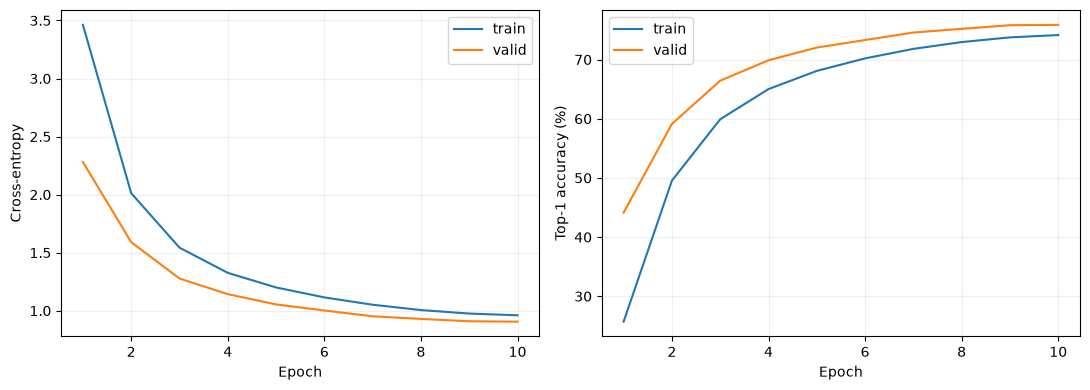

Selected epoch: 10 | validation: {'loss': 0.9056019981204599, 'acc': 0.758695652173913, 'top5_acc': 0.9396115942028985, 'samples': 172500, 'seconds': 10.426527200033888}


In [8]:
history = read_json(RUN_DIR/'history.json')
epochs = [r['epoch'] for r in history]
fig, axes = plt.subplots(1,2,figsize=(11,4))
for split in ['train','valid']:
    axes[0].plot(epochs,[r[split]['loss'] for r in history],label=split)
    axes[1].plot(epochs,[100*r[split]['acc'] for r in history],label=split)
axes[0].set_ylabel('Cross-entropy'); axes[1].set_ylabel('Top-1 accuracy (%)')
for ax in axes: ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(RUN_DIR/'curves.png',dpi=160); plt.show()
selected = torch.load(RUN_DIR/'best.pt',map_location='cpu',weights_only=False)
model = make_model(); model.load_state_dict(selected['model_state'])
validation,_ = run_epoch(model,valid_data)
if abs(validation['acc']-selected['best_acc']) > 1e-8:
    raise AssertionError('Reloaded validation accuracy differs from checkpoint selection.')
save_json(RUN_DIR/'metrics_valid.json',dict(**validation,epoch=selected['epoch'],split='valid'))
print('Selected epoch:',selected['epoch'],'| validation:',validation)

## 8. Final held-out test (off by default)

Set `RUN_FINAL_TEST=True` only after architecture/training settings are frozen.
This reloads the validation-selected checkpoint and saves overall top-1/top-5, loss,
per-class accuracy and predictions in source order. Do not tune settings using test results.
Existing metrics are displayed instead of repeating the evaluation.

In [10]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    if (RUN_DIR/'metrics_test.json').exists():
        print('Already evaluated:',read_json(RUN_DIR/'metrics_test.json'))
    else:
        selected = torch.load(RUN_DIR/'best.pt',map_location='cpu',weights_only=False)
        model = make_model(); model.load_state_dict(selected['model_state']); model.eval()
        test_data = CachedSplit('test')
        loss_sum=correct=correct5=count=0
        per_count=np.zeros(345,dtype=np.int64); per_correct=np.zeros(345,dtype=np.int64)
        predictions=[]
        synchronize(); start=time.perf_counter()
        with torch.inference_mode():
            for x,lengths,labels in tqdm(test_data.batches(CFG['batch_size']),
                                         total=math.ceil(len(test_data)/CFG['batch_size'])):
                with autocast_context():
                    logits=model(x,lengths)
                top=logits.topk(5,dim=1).indices
                loss_sum += float(F.cross_entropy(logits.float(),labels,reduction='sum'))
                correct += int((top[:,0]==labels).sum())
                correct5 += int((top==labels[:,None]).any(1).sum()); count += len(labels)
                y=labels.cpu().numpy(); pred=top.cpu().numpy(); predictions.append(pred)
                per_count += np.bincount(y,minlength=345)
                per_correct += np.bincount(y[pred[:,0]==y],minlength=345)
        synchronize()
        metrics=dict(split='test',epoch=selected['epoch'],samples=count,loss=loss_sum/count,
                     acc=correct/count,top5_acc=correct5/count,seconds=time.perf_counter()-start,
                     checkpoint_sha256=sha256(RUN_DIR/'best.pt'),
                     sample_ids_sha256=DATA_AUDIT['test']['sample_ids_sha256'])
        np.savez_compressed(RUN_DIR/'test_predictions.npz',top5=np.concatenate(predictions),
                            labels=np.asarray(test_data.labels))
        save_json(RUN_DIR/'per_class_test.json',[
            dict(category=name,samples=int(per_count[i]),acc=float(per_correct[i]/per_count[i]))
            for i,name in enumerate(CATEGORIES)])
        save_json(RUN_DIR/'metrics_test.json',metrics)
        print(metrics)
else:
    print('Test evaluation is off. Freeze settings, then set RUN_FINAL_TEST=True.')

100%|██████████| 1348/1348 [00:09<00:00, 143.04it/s]


{'split': 'test', 'epoch': 10, 'samples': 172500, 'loss': 0.9067630484733029, 'acc': 0.7587188405797102, 'top5_acc': 0.9403652173913043, 'seconds': 9.430204600095749, 'checkpoint_sha256': '54f069c58bcf387f764effb68c7ad08df463f5148f712cf32c867b71e2b4452b', 'sample_ids_sha256': 'fabeb2734b57ee853d3ec7b5787501882f737324c26fc8f523da5c8ca838bdd8'}
